<a href="https://colab.research.google.com/github/kushal-sw/Leet-code/blob/main/house_price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using Colab cache for faster access to the 'california-housing-prices' dataset.
Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



===== MODEL EVALUATION =====
MAE: $51,810.09
RMSE: $71,131.26
R² Score: 0.6139

===== MODEL INSIGHTS =====
Average Actual Price: $205,500.31
Average Predicted Price: $204,436.07
Within $25,000: 32.87%
Within $50,000: 60.32%


,Actual Price,Predicted Price,Absolute Error
0,47700.0,63969.11,16269.11
1,45800.0,154577.11,108777.11
2,500001.0,253305.71,246695.29
3,218600.0,263740.27,45140.27
4,278000.0,267115.88,10884.12
5,158700.0,155636.01,3063.99
6,198200.0,287291.17,89091.17
7,157500.0,223893.30,66393.30
8,340000.0,257277.55,82722.45
9,446600.0,404505.89,42094.11


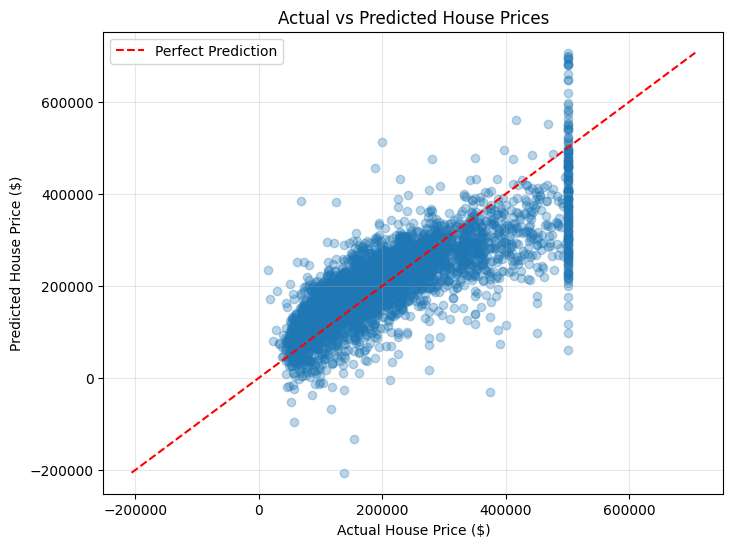

In [30]:


# 1. Import libraries
%pip install -q kagglehub

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display as show_table

# 2. Load dataset
path = kagglehub.dataset_download("camnugent/california-housing-prices")
df = pd.read_csv(os.path.join(path, "housing.csv"))

print("Dataset Shape:", df.shape)
show_table(df.head())


# 3. Split data
X = df.drop(columns=["median_house_value", "ocean_proximity"])
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Fill missing numerical values
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_train.median())


# 6. Train model
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# 7. Evaluate model
print("\n===== MODEL EVALUATION =====")
print(f"MAE: ${mean_absolute_error(y_test, y_pred):,.2f}")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_test, y_pred)):,.2f}")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")

# 8. Model insights
results = pd.DataFrame({
    "Actual Price": y_test.to_numpy(),
    "Predicted Price": y_pred
})

results["Absolute Error"] = abs(
    results["Actual Price"] - results["Predicted Price"]
)

print("\n===== MODEL INSIGHTS =====")
print(f"Average Actual Price: ${y_test.mean():,.2f}")
print(f"Average Predicted Price: ${y_pred.mean():,.2f}")
print(f"Within $25,000: {(results['Absolute Error'] <= 25000).mean() * 100:.2f}%")
print(f"Within $50,000: {(results['Absolute Error'] <= 50000).mean() * 100:.2f}%")

show_table(results.head(10).round(2))

# 9. Plot actual vs predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "r--", label="Perfect Prediction")
plt.xlabel("Actual House Price ($)")
plt.ylabel("Predicted House Price ($)")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



===== CLASSIFICATION METRICS =====
Price threshold: $179,850.00
Accuracy:  0.8074
Precision: 0.7573
Recall:    0.9010
F1 Score:  0.8229


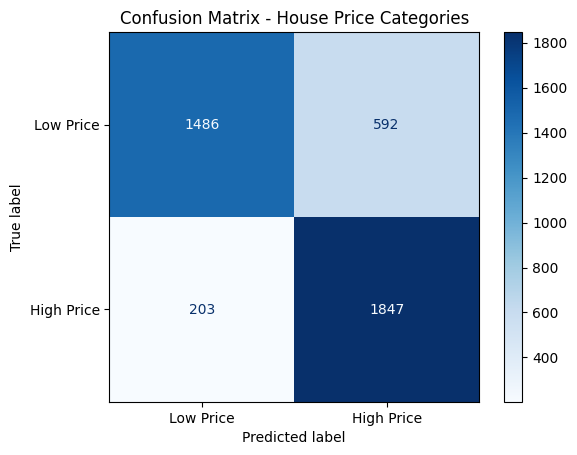

In [31]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import matplotlib.pyplot as plt
import numpy as np

# Convert house prices into Low / High categories
# Use the median of training prices as the threshold
threshold = y_train.median()

y_test_class = (y_test >= threshold).astype(int)
y_pred_class = (y_pred >= threshold).astype(int)

# Calculate classification metrics
print("===== CLASSIFICATION METRICS =====")
print(f"Price threshold: ${threshold:,.2f}")
print(f"Accuracy:  {accuracy_score(y_test_class, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_test_class, y_pred_class, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_class, y_pred_class, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_test_class, y_pred_class, zero_division=0):.4f}")

# Confusion matrix
cm = confusion_matrix(y_test_class, y_pred_class)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Price", "High Price"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - House Price Categories")
plt.show()
